Clusters : 2 | Bruit : 2


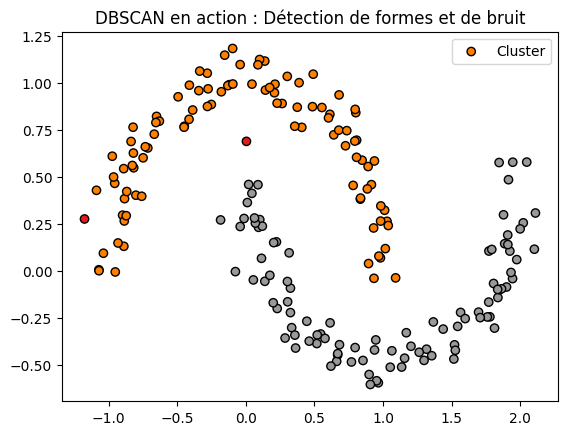

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# 2. On crée des données en forme de croissants de lune (difficile pour K-Means !)
X, _ = make_moons(n_samples=200, noise=0.08, random_state=42)

# 3. On applique DBSCAN
# eps = distance maximale entre voisins, min_samples = nb minimum de voisins
dbscan = DBSCAN(eps=0.2, min_samples=5)
labels = dbscan.fit_predict(X)

# 4. Resultat
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"Clusters : {n_clusters} | Bruit : {n_noise}")

# 5. On affiche le résultat en couleur (les points '-1' sont le bruit en gris)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="Set1", edgecolor="k", label="Cluster")
plt.title("DBSCAN en action : Détection de formes et de bruit")
plt.legend()
plt.show()

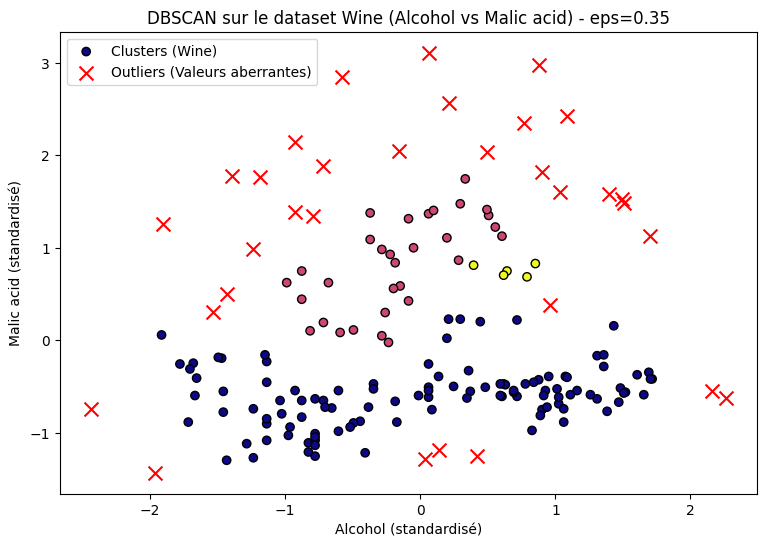

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Chargement du jeu de données Wine depuis scikit-learn[cite: 1]
wine = load_wine()

# De quel type s'agit-il ? 
# Le jeu de données est un objet de type "Bunch" (un dictionnaire enrichi qui contient 
# les données, les cibles, les noms des features, etc.)[cite: 1].

# 2. Extraction des deux premières colonnes : Alcohol (indice 0) et Malic acid (indice 1)[cite: 1]
X = wine.data[:, :2]

# 3. Standardisation des données (essentielle pour DBSCAN afin que toutes les features 
# aient la même échelle et que le paramètre eps agisse de manière uniforme)[cite: 1]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Application de DBSCAN en variant eps (autour de 0.15) et en fixant min_samples = 5[cite: 1]
# Note : 'num_samples' dans l'énoncé correspond au paramètre 'min_samples' de scikit-learn.
eps_value = 0.35  # Ajusté autour de 0.15 selon la distribution des données après standardisation
min_samples_value = 5

dbscan_wine = DBSCAN(eps=eps_value, min_samples=min_samples_value)
dbscan_wine.fit(X_scaled)

# Récupération des labels
labels_wine = dbscan_wine.labels_

# 5. Visualisation des clusters et des outliers obtenus sur le dataset Wine[cite: 1]
core_mask_wine = labels_wine != -1
outlier_mask_wine = labels_wine == -1

plt.figure(figsize=(9, 6))
# Affichage des clusters de vins
plt.scatter(X_scaled[core_mask_wine, 0], X_scaled[core_mask_wine, 1], 
            c=labels_wine[core_mask_wine], cmap='plasma', edgecolors='k', label='Clusters (Wine)')
# Affichage des outliers détectés
plt.scatter(X_scaled[outlier_mask_wine, 0], X_scaled[outlier_mask_wine, 1], 
            color='red', marker='x', s=100, label='Outliers (Valeurs aberrantes)')

plt.title(f'DBSCAN sur le dataset Wine (Alcohol vs Malic acid) - eps={eps_value}')
plt.xlabel('Alcohol (standardisé)')
plt.ylabel('Malic acid (standardisé)')
plt.legend()
plt.show()